<a href="https://colab.research.google.com/github/MOR1968/Analyse-exploratoire-des-donn-es-Jeu-de-donn-es-sur-les-prix-des-ordinateurs-portables/blob/main/Analyse_exploratoire_des_donn%C3%A9es_%E2%80%93_Jeu_de_donn%C3%A9es_sur_les_prix_des_ordinateurs_portables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🎯 Objectifs

Après avoir terminé ce labo, vous serez capable de :

📊 Visualiser les motifs individuels de chaque caractéristique

📈 Réaliser une analyse statistique descriptive sur le jeu de données

🗂️ Utiliser les regroupements et les tableaux croisés dynamiques pour étudier l’effet des variables catégorielles sur le prix

🔗 Utiliser la corrélation de Pearson pour mesurer l’interdépendance entre les variables

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:

df = pd.read_csv("laptops.csv", header=0)

In [ ]:
df.head(5)

,Unnamed: 0.1,Unnamed: 0,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,0,0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,1,1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,2,2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,3,3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,4,4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0


### **Tache 1 **: 📊 Visualiser les motifs individuels de chaque caractéristique

Caractéristiques à valeurs continues
Générez des graphiques de régression pour chacun des paramètres "CPU_frequency", "Screen_Size_inch" et "Weight_pounds" par rapport à "Price".
Affichez également la valeur de la corrélation de chaque caractéristique avec "Price".

(0.0, 3974.15)

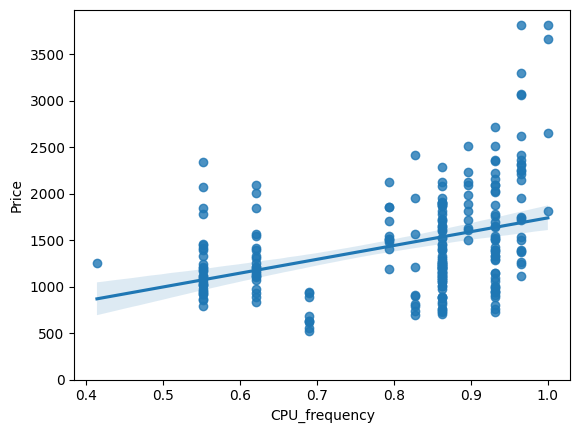

In [ ]:
sns.regplot(x="CPU_frequency", y="Price", data=df)
plt.ylim(0,)

(0.0, 3974.15)

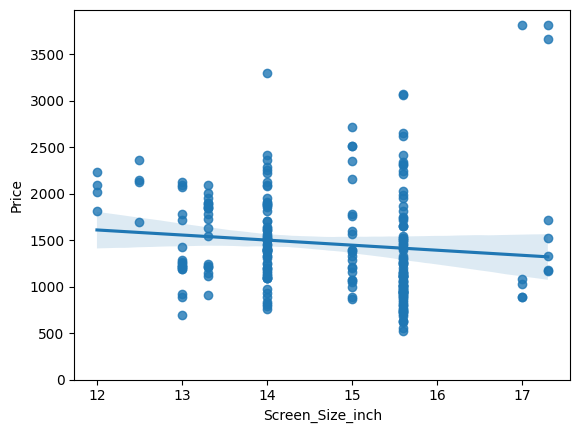

In [ ]:
sns.regplot(x="Screen_Size_inch", y="Price", data=df)
plt.ylim(0,)

(0.0, 3974.15)

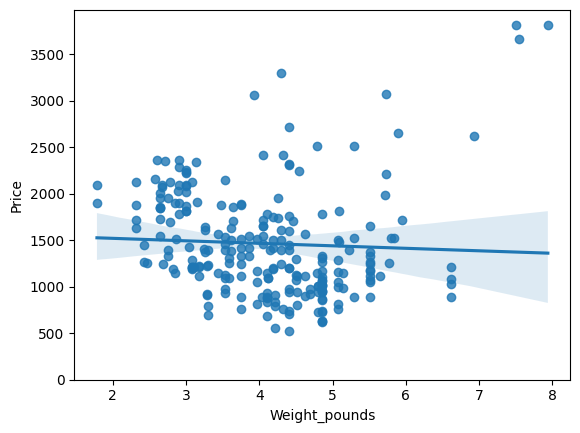

In [ ]:
sns.regplot(x="Weight_pounds", y="Price", data=df)
plt.ylim(0,)

In [ ]:
for param in ["CPU_frequency", "Screen_Size_inch","Weight_pounds"]:
    print(f"Correlation of Price and {param} is ", df[[param,"Price"]].corr())

Correlation of Price and CPU_frequency is                 CPU_frequency     Price
CPU_frequency       1.000000  0.366666
Price               0.366666  1.000000
Correlation of Price and Screen_Size_inch is                    Screen_Size_inch     Price
Screen_Size_inch          1.000000 -0.110644
Price                    -0.110644  1.000000
Correlation of Price and Weight_pounds is                 Weight_pounds     Price
Weight_pounds       1.000000 -0.050312
Price              -0.050312  1.000000


Interprétation : "CPU_frequency" présente une corrélation positive de 36 % avec le prix des ordinateurs portables.
Les deux autres paramètres ont une corrélation faible avec le prix.

**Caractéristiques catégorielles**

Générez des boxplots pour les différentes caractéristiques qui contiennent des valeurs catégorielles.
Ces caractéristiques sont : "Category", "GPU", "OS", "CPU_core", "RAM_GB", "Storage_GB_SSD".

<Axes: xlabel='Category', ylabel='Price'>

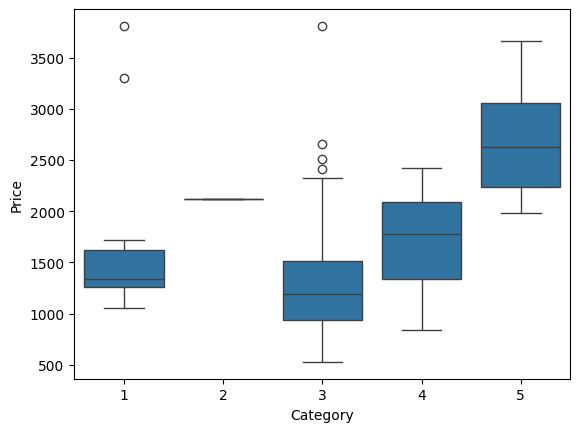

In [ ]:
#Category
sns.boxplot(x="Category", y="Price", data=df)

<Axes: xlabel='GPU', ylabel='Price'>

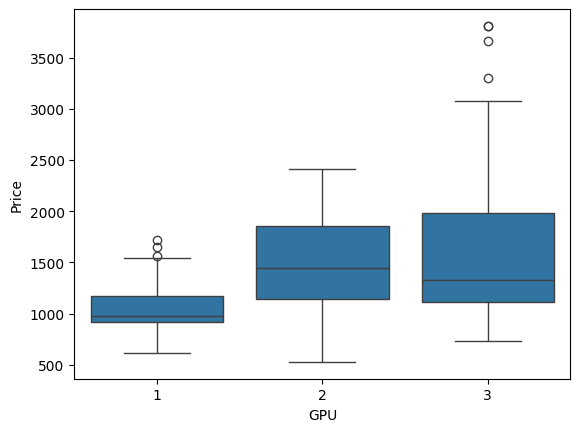

In [ ]:
#GPU
sns.boxplot(x="GPU", y="Price", data=df)

<Axes: xlabel='OS', ylabel='Price'>

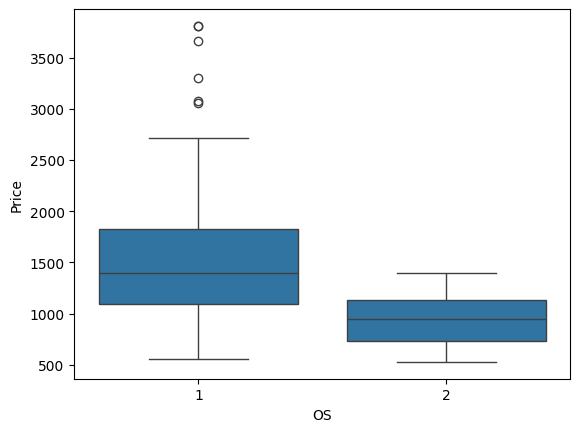

In [ ]:
#OS
sns.boxplot(x="OS", y="Price", data=df)

<Axes: xlabel='CPU_core', ylabel='Price'>

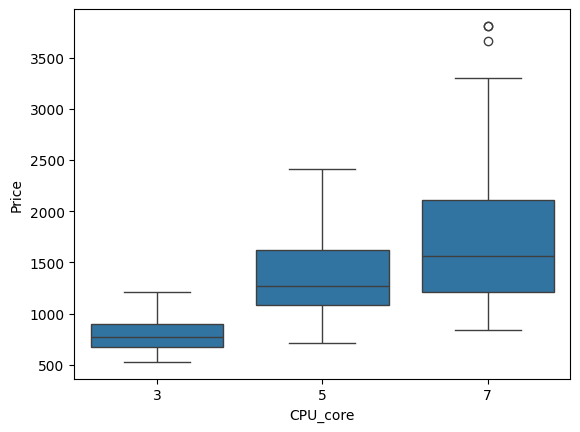

In [ ]:
#CPU_core
sns.boxplot(x="CPU_core", y="Price", data=df)

<Axes: xlabel='RAM_GB', ylabel='Price'>

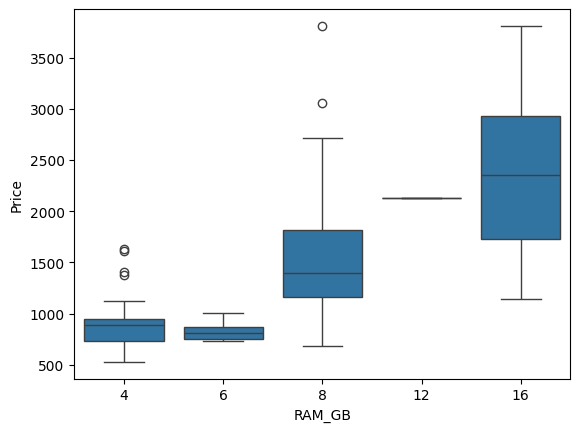

In [ ]:
sns.boxplot(x="RAM_GB", y="Price", data=df)

<Axes: xlabel='Storage_GB_SSD', ylabel='Price'>

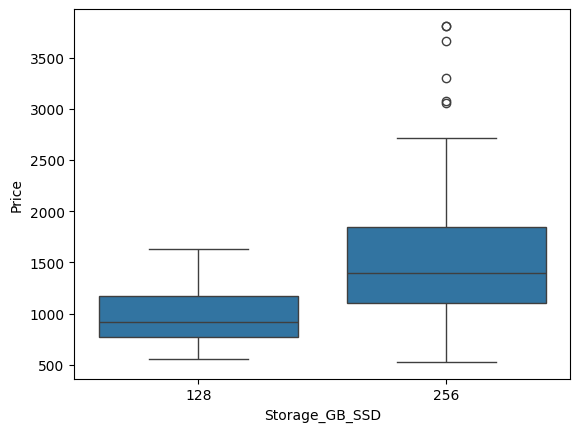

In [ ]:
sns.boxplot(x="Storage_GB_SSD", y="Price", data=df)

### **Tâche 2** – Analyse statistique descriptive



Générez la description statistique de toutes les caractéristiques utilisées dans le jeu de données.
Incluez également les types de données "object".

In [ ]:
print(df.describe())
print(df.describe(include=['object']))

       Unnamed: 0.1  Unnamed: 0    Category         GPU          OS  \
count    238.000000  238.000000  238.000000  238.000000  238.000000   
mean     118.500000  118.500000    3.205882    2.151261    1.058824   
std       68.848868   68.848868    0.776533    0.638282    0.235790   
min        0.000000    0.000000    1.000000    1.000000    1.000000   
25%       59.250000   59.250000    3.000000    2.000000    1.000000   
50%      118.500000  118.500000    3.000000    2.000000    1.000000   
75%      177.750000  177.750000    4.000000    3.000000    1.000000   
max      237.000000  237.000000    5.000000    3.000000    2.000000   

         CPU_core  Screen_Size_inch  CPU_frequency      RAM_GB  \
count  238.000000        238.000000     238.000000  238.000000   
mean     5.630252         14.688655       0.813822    7.882353   
std      1.241787          1.166045       0.141860    2.482603   
min      3.000000         12.000000       0.413793    4.000000   
25%      5.000000         14.0

### **Tâche 3** – GroupBy et tableaux croisés dynamiques

Regroupez les paramètres "GPU", "CPU_core" et "Price" pour créer un tableau croisé dynamique et visualisez cette relation à l’aide d’un graphe pcolor.

In [ ]:
#Regroupez les paramètres
df_gptest = df[['GPU','CPU_core','Price']]
grouped_test1 = df_gptest.groupby(['GPU','CPU_core'],as_index=False).mean()
print(grouped_test1)

   GPU  CPU_core        Price
0    1         3   769.250000
1    1         5   998.500000
2    1         7  1167.941176
3    2         3   785.076923
4    2         5  1462.197674
5    2         7  1744.621622
6    3         3   784.000000
7    3         5  1220.680000
8    3         7  1945.097561


In [ ]:
#Creation de la table pivo
grouped_pivot = grouped_test1.pivot(index='GPU',columns='CPU_core')
grouped_pivot

Price                          
CPU_core           3            5            7
GPU                                           
1         769.250000   998.500000  1167.941176
2         785.076923  1462.197674  1744.621622
3         784.000000  1220.680000  1945.097561

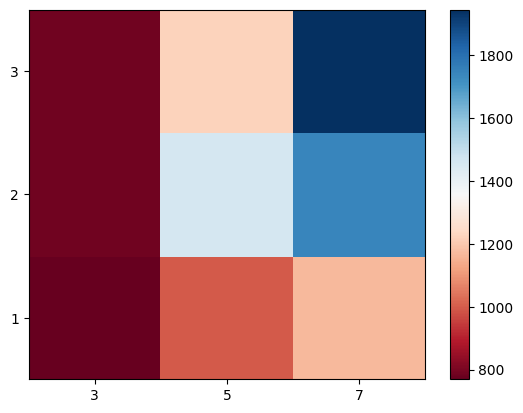

In [ ]:
#Voyons le plot
fig, ax = plt.subplots()
im = ax.pcolor(grouped_pivot, cmap='RdBu')

#label names
row_labels = grouped_pivot.columns.levels[1]
col_labels = grouped_pivot.index

#move ticks and labels to the center
ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, minor=False)

#insert labels
ax.set_xticklabels(row_labels, minor=False)
ax.set_yticklabels(col_labels, minor=False)

fig.colorbar(im)

**Tâche 4**  Corrélation de Pearson et valeurs p


Utilisez la fonction scipy.stats.pearsonr() pour évaluer le coefficient de Pearson et les valeurs p pour chaque paramètre testé ci-dessus.
Cela vous aidera à déterminer les paramètres les plus susceptibles d’avoir un impact significatif sur le prix des ordinateurs portables.

In [ ]:

from scipy import stats
for param in ['RAM_GB','CPU_frequency','Storage_GB_SSD','Screen_Size_inch','Weight_pounds','CPU_core','OS','GPU','Category']:
    pearson_coef, p_value = stats.pearsonr(df[param], df['Price'])
    print(param)
    #print("The Pearson Correlation Coefficient for ",param," is", pearson_coef, " with a P-value of P =", p_value)
    print("Le coefficient de corrélation de Pearson est", param, "avec une valeur p de P =", p_value)

RAM_GB
Le coefficient de corrélation de Pearson est RAM_GB avec une valeur p de P = 3.6815606288428415e-20
CPU_frequency
Le coefficient de corrélation de Pearson est CPU_frequency avec une valeur p de P = 5.502463350713357e-09
Storage_GB_SSD
Le coefficient de corrélation de Pearson est Storage_GB_SSD avec une valeur p de P = 0.0001489892319172414
Screen_Size_inch
Le coefficient de corrélation de Pearson est Screen_Size_inch avec une valeur p de P = 0.08853397846830661
Weight_pounds
Le coefficient de corrélation de Pearson est Weight_pounds avec une valeur p de P = 0.4397693853433896
CPU_core
Le coefficient de corrélation de Pearson est CPU_core avec une valeur p de P = 7.912950127009183e-14
OS
Le coefficient de corrélation de Pearson est OS avec une valeur p de P = 0.0005696642559246719
GPU
Le coefficient de corrélation de Pearson est GPU avec une valeur p de P = 6.16694969836445e-06
Category
Le coefficient de corrélation de Pearson est Category avec une valeur p de P = 7.2256962358065